# Cookie Cats A/B 미니분석

## 1. 가설과 지표 (데이터 보기 전 작성)

- 가설: 장벽을 30레벨에서 40레벨로 미루면 7일 리텐션이 달라진다
  - 귀무가설: 차이 없음 / 양측 검정 / 유의수준 0.05
- 주지표: `retention_7` / 보조지표: `retention_1` / 가드레일: `sum_gamerounds`
- 주지표를 고른 이유: 1일 리텐션은 게임에 대한 첫인상이라 게이트에 닿기 전 이탈이 많이 섞여 있을 수 있고, 게이트를 겪은 뒤에도 돌아오는지는 7일 리텐션에서 볼 수 있다고 판단해 주지표로 설정함.

## 2. 데이터 확인

확인할 것:
1. 행 수, `userid` 중복, 결측
2. `sum_gamerounds` 분포와 최댓값. 극단값은 지우지 않고 표시만 하고, 포함·제외 결과를 나란히 본다
3. 그룹별 0라운드 유저 비율

집계는 DuckDB SQL로 한다.

### 2-0. 데이터 불러오기

CSV를 DuckDB 테이블 `cc`로 읽고 앞 5행과 컬럼 타입을 본다.

In [1]:
import duckdb
import matplotlib.pyplot as plt

con = duckdb.connect()
con.execute("CREATE TABLE cc AS SELECT * FROM read_csv_auto('data/cookie_cats.csv')")
con.sql("SELECT * FROM cc LIMIT 5").df()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [2]:
con.sql("DESCRIBE cc").df()[['column_name', 'column_type']]

,column_name,column_type
0,userid,BIGINT
1,version,VARCHAR
2,sum_gamerounds,BIGINT
3,retention_1,BOOLEAN
4,retention_7,BOOLEAN


### 2-1. 행 수, `userid` 중복, 결측

`n_rows`와 `n_unique_userid`가 같으면 한 행이 한 유저다. 결측은 컬럼별로 센다.

In [3]:
con.sql("""
SELECT
    COUNT(*)                              AS n_rows,
    COUNT(DISTINCT userid)                AS n_unique_userid,
    COUNT(*) - COUNT(DISTINCT userid)     AS n_dup_userid,
    COUNT(*) - COUNT(userid)              AS null_userid,
    COUNT(*) - COUNT(version)             AS null_version,
    COUNT(*) - COUNT(sum_gamerounds)      AS null_sum_gamerounds,
    COUNT(*) - COUNT(retention_1)         AS null_retention_1,
    COUNT(*) - COUNT(retention_7)         AS null_retention_7
FROM cc
""").df().T.rename(columns={0: 'value'})

,value
n_rows,90189
n_unique_userid,90189
n_dup_userid,0
null_userid,0
null_version,0
null_sum_gamerounds,0
null_retention_1,0
null_retention_7,0


### 2-2. `sum_gamerounds` 분포와 최댓값

전체 분위수와 최댓값을 보고, 값이 큰 순서로 상위 10명을 확인한다.

In [4]:
con.sql("""
SELECT
    MIN(sum_gamerounds)                                         AS min,
    QUANTILE_CONT(sum_gamerounds, 0.25)                         AS p25,
    MEDIAN(sum_gamerounds)                                      AS median,
    QUANTILE_CONT(sum_gamerounds, 0.75)                         AS p75,
    QUANTILE_CONT(sum_gamerounds, 0.99)                         AS p99,
    QUANTILE_CONT(sum_gamerounds, 0.999)                        AS p999,
    MAX(sum_gamerounds)                                         AS max,
    ROUND(AVG(sum_gamerounds), 2)                               AS mean
FROM cc
""").df()

,min,p25,median,p75,p99,p999,max,mean
0,0,5.0,16.0,51.0,493.0,1073.624,49854,51.87


In [5]:
con.sql("""
SELECT userid, version, sum_gamerounds, retention_1, retention_7
FROM cc
ORDER BY sum_gamerounds DESC
LIMIT 10
""").df()

,userid,version,sum_gamerounds,retention_1,retention_7
0,6390605,gate_30,49854,False,True
1,871500,gate_30,2961,True,True
2,3271615,gate_40,2640,True,False
3,4832608,gate_30,2438,True,True
4,5346171,gate_40,2294,True,True
5,5133952,gate_30,2251,True,True
6,9640085,gate_30,2156,True,True
7,4090246,gate_40,2124,True,True
8,9791599,gate_40,2063,True,True
9,725080,gate_40,2015,True,True


### 2-3. 극단값 표시

최댓값 49,854는 2위(2,961)의 약 17배로 나머지와 동떨어져 있다. 행은 지우지 않고 `is_extreme` 플래그만 붙인다.

- **확정 기준**: userid 6390605 한 명만 극단값으로 표시
- 이후 처리 방침
  - 라운드 수 통계(`sum_gamerounds`): 이 유저를 **제외**하고 계산
  - 리텐션 집계·검정: 이 유저를 **포함한 결과와 제외한 결과를 둘 다** 제시

In [6]:
EXTREME_USERID = 6390605

con.execute(f"""
CREATE OR REPLACE TABLE cc_flag AS
SELECT *,
       userid = {EXTREME_USERID} AS is_extreme
FROM cc
""")
con.sql("SELECT * FROM cc_flag WHERE is_extreme").df()

,userid,version,sum_gamerounds,retention_1,retention_7,is_extreme
0,6390605,gate_30,49854,False,True,True


### 2-4. 극단값 포함·제외 비교 (그룹별)

극단값 1명이 평균과 표준편차를 얼마나 바꾸는지 그룹별로 비교한다. 중앙값은 거의 그대로일 것으로 예상한다.

In [7]:
con.sql("""
WITH base AS (
    SELECT 'all'               AS sample, * FROM cc_flag
    UNION ALL
    SELECT 'excl_extreme'      AS sample, * FROM cc_flag WHERE NOT is_extreme
)
SELECT
    sample,
    version,
    COUNT(*)                              AS n_users,
    ROUND(AVG(sum_gamerounds), 2)         AS mean,
    ROUND(STDDEV_SAMP(sum_gamerounds), 2) AS std,
    MEDIAN(sum_gamerounds)                AS median,
    MAX(sum_gamerounds)                   AS max
FROM base
GROUP BY sample, version
ORDER BY sample, version
""").df()

,sample,version,n_users,mean,std,median,max
0,all,gate_30,44700,52.46,256.72,17.0,49854
1,all,gate_40,45489,51.30,103.29,16.0,2640
2,excl_extreme,gate_30,44699,51.34,102.06,17.0,2961
3,excl_extreme,gate_40,45489,51.30,103.29,16.0,2640


분포 그림: 왼쪽은 극단값 포함 상자그림, 오른쪽은 극단값 제외 상자그림이다.

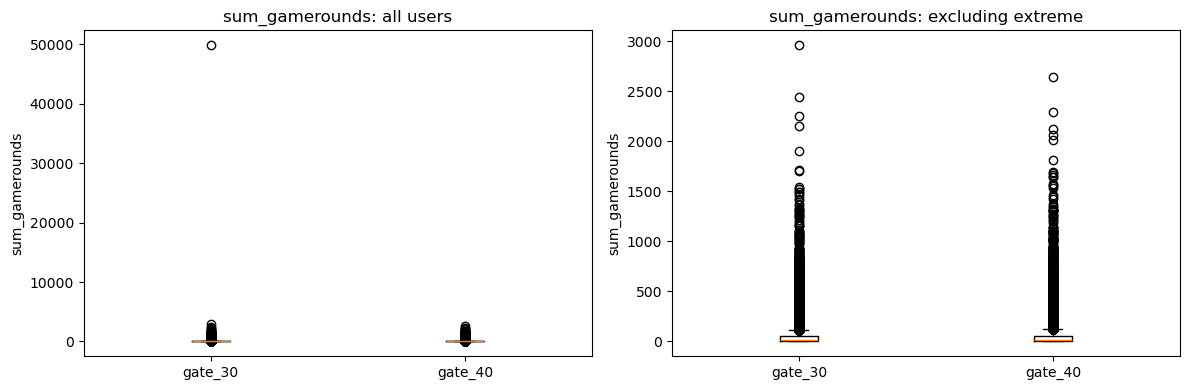

In [8]:
df_flag = con.sql("SELECT version, sum_gamerounds, is_extreme FROM cc_flag").df()
groups = ['gate_30', 'gate_40']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (title, d) in zip(axes, [('all users', df_flag),
                                 ('excluding extreme', df_flag[~df_flag['is_extreme']])]):
    ax.boxplot([d.loc[d['version'] == g, 'sum_gamerounds'] for g in groups])
    ax.set_xticks([1, 2], groups)
    ax.set_title(f'sum_gamerounds: {title}')
    ax.set_ylabel('sum_gamerounds')
plt.tight_layout()
plt.show()

### 2-5. 그룹별 0라운드 유저 비율

설치 후 한 판도 안 한 유저 비율이 두 그룹에서 비슷한지 본다.

In [9]:
con.sql("""
SELECT
    version,
    COUNT(*)                                          AS n_users,
    COUNT(*) FILTER (WHERE sum_gamerounds = 0)        AS n_zero_round,
    ROUND(AVG((sum_gamerounds = 0)::INT) * 100, 2)    AS zero_round_pct
FROM cc
GROUP BY version
ORDER BY version
""").df()

,version,n_users,n_zero_round,zero_round_pct
0,gate_30,44700,1937,4.33
1,gate_40,45489,2057,4.52


### 2단계 정리

- 90,189행, `userid` 중복 0, 모든 컬럼 결측 0 → 한 행 = 한 유저
- `sum_gamerounds`는 오른쪽 꼬리가 긴 분포 (중앙값 16, p99 493, 최댓값 49,854)
- 극단값: gate_30의 userid 6390605 (49,854라운드, 2위 2,961의 약 17배). 지우지 않고 `is_extreme`으로 표시
  - 빼면 gate_30 평균 52.46 → 51.34, 표준편차 256.72 → 102.06, 중앙값은 17로 그대로
  - 이 유저는 `retention_1` = False, `retention_7` = True
- 0라운드 유저 비율: gate_30 4.33%, gate_40 4.52%로 비슷
- 처리 방침(확정): 라운드 수 통계는 이 유저 제외, 리텐션은 포함·제외 결과를 둘 다 제시

## 3. 실험 품질 점검 (SRM)

두 그룹이 설계대로 50:50으로 배정되었는지 카이제곱 적합도 검정으로 확인한다.

- 배정 자체를 점검하는 단계라서 극단값 유저를 포함한 전체 유저로 본다 (1명이라 결과에 영향 없음)
- 판단 기준(가이드): p값이 매우 작으면(0.001 미만) 배정 오류를 의심하고 한계로 적는다

In [10]:
srm = con.sql("""
SELECT version, COUNT(*) AS n_users
FROM cc
GROUP BY version
ORDER BY version
""").df()
srm['ratio'] = (srm['n_users'] / srm['n_users'].sum()).round(4)
srm

,version,n_users,ratio
0,gate_30,44700,0.4956
1,gate_40,45489,0.5044


In [11]:
from scipy.stats import chisquare

observed = srm['n_users'].to_numpy()
expected = [observed.sum() / 2] * 2
chi2, p_srm = chisquare(observed, f_exp=expected)
print(f'관측: {dict(zip(srm.version, observed.tolist()))}')
print(f'기대: {expected[0]:.1f} / {expected[1]:.1f}')
print(f'chi2 = {chi2:.3f}, p = {p_srm:.4f}')
print('배정 오류 의심 (p < 0.001):', p_srm < 0.001)

관측: {'gate_30': 44700, 'gate_40': 45489}
기대: 45094.5 / 45094.5
chi2 = 6.902, p = 0.0086
배정 오류 의심 (p < 0.001): False


### 3단계 정리

- gate_30 44,700명(49.56%) / gate_40 45,489명(50.44%), 차이 789명
- 카이제곱 적합도 검정: chi2 = 6.902, p = 0.0086
- 가이드 기준(p < 0.001)에는 해당하지 않아 배정 오류로 보지는 않는다
- 다만 p < 0.05라서 50:50에서 약간 벗어난 것은 우연으로만 보기 어렵다. 결론의 한계에 함께 적는다

## 4. 지표 집계 (DuckDB SQL)

그룹별 유저 수, `retention_1`·`retention_7` 비율, 라운드 수 중앙값을 한 쿼리로 집계한다.

- 리텐션: 극단값 포함(`_all`)과 제외(`_excl`)를 나란히 표시
- 라운드 수: 극단값 제외 기준으로만 계산

In [12]:
summary = con.sql("""
SELECT
    version,
    COUNT(*)                                                             AS n_users_all,
    COUNT(*) FILTER (WHERE NOT is_extreme)                               AS n_users_excl,
    ROUND(AVG(retention_1::INT) * 100, 2)                                AS ret1_all_pct,
    ROUND(AVG(retention_1::INT) FILTER (WHERE NOT is_extreme) * 100, 2)  AS ret1_excl_pct,
    ROUND(AVG(retention_7::INT) * 100, 2)                                AS ret7_all_pct,
    ROUND(AVG(retention_7::INT) FILTER (WHERE NOT is_extreme) * 100, 2)  AS ret7_excl_pct,
    MEDIAN(sum_gamerounds) FILTER (WHERE NOT is_extreme)                 AS median_rounds_excl
FROM cc_flag
GROUP BY version
ORDER BY version
""").df()
summary

,version,n_users_all,n_users_excl,ret1_all_pct,ret1_excl_pct,ret7_all_pct,ret7_excl_pct,median_rounds_excl
0,gate_30,44700,44699,44.82,44.82,19.02,19.02,17.0
1,gate_40,45489,45489,44.23,44.23,18.20,18.20,16.0


### 4단계 정리

| version | 유저 수 | retention_1 | retention_7 | 라운드 수 중앙값(극단값 제외) |
|---|---|---|---|---|
| gate_30 | 44,700 (제외 시 44,699) | 44.82% | 19.02% | 17 |
| gate_40 | 45,489 | 44.23% | 18.20% | 16 |

- 극단값 1명을 빼도 리텐션 비율은 소수 둘째 자리까지 같다
- 단순 비율로는 gate_30이 1일 0.59%p, 7일 0.82%p 높다. 유의성은 5단계에서 검정

## 5. 검정

`retention_7`(주지표)과 `retention_1`(보조지표) 각각에 대해 두 비율 z검정을 한다.

- 검정: `statsmodels.stats.proportion.proportions_ztest`, 양측, 유의수준 0.05
- 차이: gate_30 − gate_40 (%p)
- 95% 신뢰구간: `confint_proportions_2indep` (Wald 방식, 차이 기준)
- 극단값 유저(userid 6390605) 포함(`all`)과 제외(`excl_extreme`) 두 버전을 모두 계산

### 5-1. 그룹별 재방문 유저 수 집계 (DuckDB SQL)

검정에 넣을 성공 횟수(재방문 유저 수)와 전체 유저 수를 표본 버전별로 센다.

In [13]:
counts = con.sql("""
WITH base AS (
    SELECT 'all'          AS sample, * FROM cc_flag
    UNION ALL
    SELECT 'excl_extreme' AS sample, * FROM cc_flag WHERE NOT is_extreme
)
SELECT
    sample,
    version,
    COUNT(*)                                AS n_users,
    COUNT(*) FILTER (WHERE retention_1)     AS n_ret1,
    COUNT(*) FILTER (WHERE retention_7)     AS n_ret7
FROM base
GROUP BY sample, version
ORDER BY sample, version
""").df()
counts

,sample,version,n_users,n_ret1,n_ret7
0,all,gate_30,44700,20034,8502
1,all,gate_40,45489,20119,8279
2,excl_extreme,gate_30,44699,20034,8501
3,excl_extreme,gate_40,45489,20119,8279


### 5-2. 두 비율 z검정과 차이의 95% 신뢰구간

주지표(`retention_7`)를 먼저, 보조지표(`retention_1`)를 다음에 표시한다.

In [14]:
import pandas as pd
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

rows = []
for metric, col in [('retention_7 (주지표)', 'n_ret7'), ('retention_1 (보조)', 'n_ret1')]:
    for sample in ['all', 'excl_extreme']:
        d = counts[counts['sample'] == sample].set_index('version')
        x30, n30 = d.loc['gate_30', col], d.loc['gate_30', 'n_users']
        x40, n40 = d.loc['gate_40', col], d.loc['gate_40', 'n_users']

        z, p = proportions_ztest([x30, x40], [n30, n40], alternative='two-sided')
        lo, hi = confint_proportions_2indep(x30, n30, x40, n40,
                                            method='wald', compare='diff', alpha=0.05)
        rows.append({
            'metric': metric,
            'sample': sample,
            'gate_30 (%)': round(x30 / n30 * 100, 2),
            'gate_40 (%)': round(x40 / n40 * 100, 2),
            'diff (%p)': round((x30 / n30 - x40 / n40) * 100, 2),
            'CI 95% low (%p)': round(lo * 100, 2),
            'CI 95% high (%p)': round(hi * 100, 2),
            'z': round(z, 3),
            'p_value': round(p, 4),
        })

test_result = pd.DataFrame(rows)
test_result

,metric,sample,gate_30 (%),gate_40 (%),diff (%p),CI 95% low (%p),CI 95% high (%p),z,p_value
0,retention_7 (주지표),all,19.02,18.20,0.82,0.31,1.33,3.164,0.0016
1,retention_7 (주지표),excl_extreme,19.02,18.20,0.82,0.31,1.33,3.157,0.0016
2,retention_1 (보조),all,44.82,44.23,0.59,-0.06,1.24,1.784,0.0744
3,retention_1 (보조),excl_extreme,44.82,44.23,0.59,-0.06,1.24,1.787,0.0739


### 5단계 해석

7일 리텐션은 양측 검정에서 귀무가설을 기각했고(p = 0.0016), 차이(gate_30 − gate_40)의 95% 신뢰구간 [0.31, 1.33]이 모두 0보다 크므로 게이트를 40레벨로 옮기면 7일 리텐션이 낮아진다고 판단했다. 반면 보조지표인 1일 리텐션은 p=0.074로 귀무가설을 기각하지 못해 두 게이트 사이의 차이를 확인하지 못했다.

## 6. 부트스트랩

5단계 z검정은 정규근사에 기반한다. 분포 가정 없이 같은 결론이 나오는지 부트스트랩으로 확인한다.

- 각 그룹 안에서 유저를 복원추출(그룹 크기 그대로)해 리텐션 비율을 다시 계산하고, 이를 1만 번 반복
- 한 번 뽑은 유저 표본으로 `retention_7`과 `retention_1`을 함께 계산 (같은 재표본을 두 지표에 사용)
- 차이: gate_30 − gate_40 (%p)
- 난수 시드 고정: `np.random.default_rng(42)`
- 극단값 유저 포함(`all`)과 제외(`excl_extreme`) 두 버전을 모두 계산

### 6-1. 부트스트랩 실행

유저 단위 데이터를 DuckDB에서 꺼내 NumPy로 재표본을 만든다. 메모리를 아끼려고 500번씩 나눠서 뽑는다.

In [15]:
import numpy as np

N_BOOT = 10_000
CHUNK = 500
SEED = 42

users = con.sql("""
SELECT version, is_extreme, retention_1::INT AS r1, retention_7::INT AS r7
FROM cc_flag
""").df()

def bootstrap_rates(r1, r7, rng, n_boot=N_BOOT, chunk=CHUNK):
    """한 그룹에서 복원추출을 n_boot번 해서 재표본별 (ret1, ret7) 비율을 돌려준다."""
    n = len(r1)
    out1, out7 = [], []
    for start in range(0, n_boot, chunk):
        size = min(chunk, n_boot - start)
        idx = rng.integers(0, n, size=(size, n))
        out1.append(r1[idx].mean(axis=1))
        out7.append(r7[idx].mean(axis=1))
    return np.concatenate(out1), np.concatenate(out7)

rng = np.random.default_rng(SEED)
boot_diff = {}  # (sample, metric) -> 차이(%p) 배열
for sample in ['all', 'excl_extreme']:
    d = users if sample == 'all' else users[~users['is_extreme']]
    rates = {}
    for g in ['gate_30', 'gate_40']:
        gd = d[d['version'] == g]
        rates[g] = bootstrap_rates(gd['r1'].to_numpy(), gd['r7'].to_numpy(), rng)
    boot_diff[(sample, 'retention_1')] = (rates['gate_30'][0] - rates['gate_40'][0]) * 100
    boot_diff[(sample, 'retention_7')] = (rates['gate_30'][1] - rates['gate_40'][1]) * 100

{k: v.shape for k, v in boot_diff.items()}

{('all', 'retention_1'): (10000,),
 ('all', 'retention_7'): (10000,),
 ('excl_extreme', 'retention_1'): (10000,),
 ('excl_extreme', 'retention_7'): (10000,)}

### 6-2. 차이 분포

극단값 포함(`all`) 기준. 빨간 점선은 부트스트랩 95% 구간(2.5%, 97.5% 분위수), 검은 실선은 0이다.

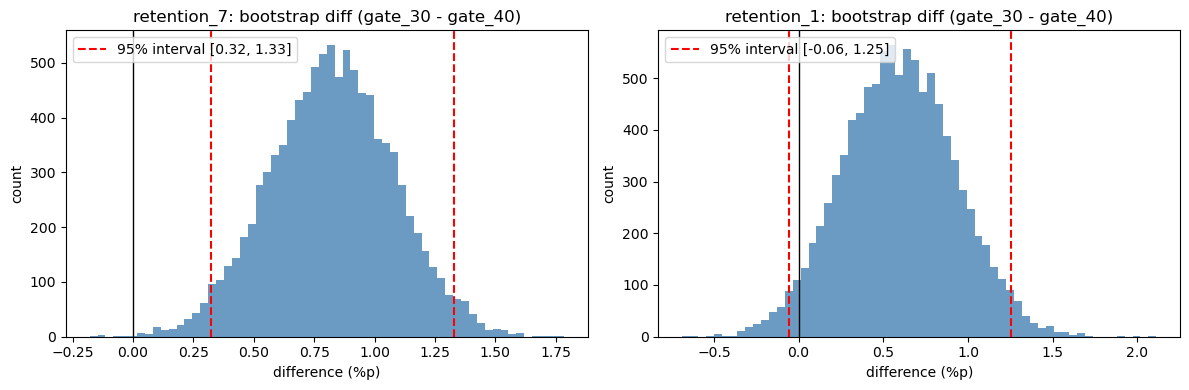

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['retention_7', 'retention_1']):
    diff = boot_diff[('all', metric)]
    lo, hi = np.percentile(diff, [2.5, 97.5])
    ax.hist(diff, bins=60, color='steelblue', alpha=0.8)
    ax.axvline(lo, color='red', linestyle='--', label=f'95% interval [{lo:.2f}, {hi:.2f}]')
    ax.axvline(hi, color='red', linestyle='--')
    ax.axvline(0, color='black', linewidth=1)
    ax.set_title(f'{metric}: bootstrap diff (gate_30 - gate_40)')
    ax.set_xlabel('difference (%p)')
    ax.set_ylabel('count')
    ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

### 6-3. 부트스트랩 95% 구간과 gate_30이 더 높을 확률

- 95% 구간: 차이 분포의 2.5%, 97.5% 분위수 (percentile 방식)
- `P(gate_30 > gate_40)`: 1만 개 차이 중 0보다 큰 비율

In [17]:
boot_rows = []
for metric, label in [('retention_7', 'retention_7 (주지표)'), ('retention_1', 'retention_1 (보조)')]:
    for sample in ['all', 'excl_extreme']:
        diff = boot_diff[(sample, metric)]
        lo, hi = np.percentile(diff, [2.5, 97.5])
        boot_rows.append({
            'metric': label,
            'sample': sample,
            'boot mean diff (%p)': round(diff.mean(), 2),
            'boot 2.5% (%p)': round(lo, 2),
            'boot 97.5% (%p)': round(hi, 2),
            'P(gate_30 > gate_40)': round((diff > 0).mean(), 4),
        })

boot_result = pd.DataFrame(boot_rows)
boot_result

,metric,sample,boot mean diff (%p),boot 2.5% (%p),boot 97.5% (%p),P(gate_30 > gate_40)
0,retention_7 (주지표),all,0.82,0.32,1.33,0.9993
1,retention_7 (주지표),excl_extreme,0.82,0.31,1.33,0.9992
2,retention_1 (보조),all,0.59,-0.06,1.25,0.9616
3,retention_1 (보조),excl_extreme,0.59,-0.05,1.25,0.9638


### 6-4. z검정 신뢰구간과 비교

5단계 `test_result`(Wald 95% 신뢰구간)와 부트스트랩 95% 구간을 나란히 놓는다. 구간 폭 = 상한 − 하한.

In [18]:
compare = test_result[['metric', 'sample', 'diff (%p)', 'CI 95% low (%p)', 'CI 95% high (%p)']].merge(
    boot_result[['metric', 'sample', 'boot 2.5% (%p)', 'boot 97.5% (%p)', 'P(gate_30 > gate_40)']],
    on=['metric', 'sample'],
)
compare['z CI width (%p)'] = (compare['CI 95% high (%p)'] - compare['CI 95% low (%p)']).round(2)
compare['boot width (%p)'] = (compare['boot 97.5% (%p)'] - compare['boot 2.5% (%p)']).round(2)
compare = compare.rename(columns={'CI 95% low (%p)': 'z CI low (%p)', 'CI 95% high (%p)': 'z CI high (%p)'})
compare

,metric,sample,diff (%p),z CI low (%p),z CI high (%p),boot 2.5% (%p),boot 97.5% (%p),P(gate_30 > gate_40),z CI width (%p),boot width (%p)
0,retention_7 (주지표),all,0.82,0.31,1.33,0.32,1.33,0.9993,1.02,1.01
1,retention_7 (주지표),excl_extreme,0.82,0.31,1.33,0.31,1.33,0.9992,1.02,1.02
2,retention_1 (보조),all,0.59,-0.06,1.24,-0.06,1.25,0.9616,1.30,1.31
3,retention_1 (보조),excl_extreme,0.59,-0.06,1.24,-0.05,1.25,0.9638,1.30,1.30


### 6-5. 효과 크기 (7일 리텐션)

기준은 기존 설정인 gate_30이다 (가설: 30레벨 → 40레벨로 미룰 때의 변화).

- 상대 변화(%) = (gate_40 − gate_30) / gate_30 × 100
- 신규 유저 1만 명당 = (gate_30 − gate_40) × 10,000 → 게이트를 40으로 옮기면 7일 뒤 돌아오는 유저가 몇 명 줄어드는지
- 점추정과 함께 z검정 신뢰구간, 부트스트랩 구간의 양 끝도 같은 방식으로 환산 (극단값 포함 `all` 기준, 상대 변화는 gate_30 비율을 고정하고 환산)

In [19]:
d = counts[counts['sample'] == 'all'].set_index('version')
p30 = d.loc['gate_30', 'n_ret7'] / d.loc['gate_30', 'n_users']
p40 = d.loc['gate_40', 'n_ret7'] / d.loc['gate_40', 'n_users']

z_row = test_result[(test_result['metric'] == 'retention_7 (주지표)') & (test_result['sample'] == 'all')].iloc[0]
b_row = boot_result[(boot_result['metric'] == 'retention_7 (주지표)') & (boot_result['sample'] == 'all')].iloc[0]

def effect(diff_pp):
    """차이(gate_30 - gate_40, %p)를 상대 변화(%)와 1만 명당 인원으로 환산."""
    return round(-diff_pp / (p30 * 100) * 100, 2), round(diff_pp / 100 * 10_000, 1)

eff_rows = []
for label, diff_pp in [
    ('점추정', (p30 - p40) * 100),
    ('z CI 하한', z_row['CI 95% low (%p)']),
    ('z CI 상한', z_row['CI 95% high (%p)']),
    ('boot 2.5%', b_row['boot 2.5% (%p)']),
    ('boot 97.5%', b_row['boot 97.5% (%p)']),
]:
    rel, per10k = effect(diff_pp)
    eff_rows.append({
        '구분': label,
        'diff gate_30 − gate_40 (%p)': round(diff_pp, 2),
        '상대 변화 gate_40 vs gate_30 (%)': rel,
        '1만 명당 7일 재방문 감소 (명)': per10k,
    })

effect_size = pd.DataFrame(eff_rows)
print(f'gate_30 7일 리텐션 = {p30 * 100:.2f}%, gate_40 = {p40 * 100:.2f}%')
effect_size

gate_30 7일 리텐션 = 19.02%, gate_40 = 18.20%


,구분,diff gate_30 − gate_40 (%p),상대 변화 gate_40 vs gate_30 (%),1만 명당 7일 재방문 감소 (명)
0,점추정,0.82,-4.31,82.0
1,z CI 하한,0.31,-1.63,31.0
2,z CI 상한,1.33,-6.99,133.0
3,boot 2.5%,0.32,-1.68,32.0
4,boot 97.5%,1.33,-6.99,133.0


### 6단계 해석

부트스트랩 결과 7일 리텐션 차이의 95% 신뢰구간은 [0.32, 1.33]%p로 z검정 신뢰구간과 거의 유사하고, 재표본의 99.93%에서 gate_30이 더 높다는 결과가 나왔다. 두 방법이 같은 결론을 보이며, 게이트를 40레벨로 옮기면 7일 리텐션이 낮아진다는 판단이다. 효과 크기는 상대 4.3% 감소로, 신규 유저 1만 명당 7일 뒤 돌아오는 유저가 약 82명(구간 31~133명) 줄어드는 수준이다. 1일 리텐션은 96.16%의 재표본에서 gate_30이 높았지만 구간에 0이 포함되어 차이를 확인하지 못했다.

## 7. 세그먼트 (탐색용)

> **탐색적 관찰: 라운드 수는 실험 이후에 정해진 값이라 구간별 차이를 인과 효과로 해석하지 않음**

`sum_gamerounds`를 네 구간으로 나눠 그룹별 7일 리텐션을 본다. 검정과 p값은 넣지 않는다.

- 구간: `0`, `1~29`, `30~39`, `40+`
- 차이: gate_30 − gate_40 (%p)
- 극단값 유저(userid 6390605, `40+` 구간)는 포함(`all`)과 제외(`excl_extreme`)를 둘 다 표시

### 7-1. 구간 × 그룹 집계 (DuckDB SQL)

In [20]:
segment = con.sql("""
WITH base AS (
    SELECT 'all'          AS sample, * FROM cc_flag
    UNION ALL
    SELECT 'excl_extreme' AS sample, * FROM cc_flag WHERE NOT is_extreme
),
bucketed AS (
    SELECT *,
           CASE
               WHEN sum_gamerounds = 0  THEN 1
               WHEN sum_gamerounds < 30 THEN 2
               WHEN sum_gamerounds < 40 THEN 3
               ELSE 4
           END AS bucket_order,
           CASE
               WHEN sum_gamerounds = 0  THEN '0'
               WHEN sum_gamerounds < 30 THEN '1~29'
               WHEN sum_gamerounds < 40 THEN '30~39'
               ELSE '40+'
           END AS rounds_bucket
    FROM base
)
SELECT
    sample,
    rounds_bucket,
    COUNT(*) FILTER (WHERE version = 'gate_30')                                      AS n_gate_30,
    COUNT(*) FILTER (WHERE version = 'gate_40')                                      AS n_gate_40,
    ROUND(AVG(retention_7::INT) FILTER (WHERE version = 'gate_30') * 100, 2)         AS ret7_gate_30_pct,
    ROUND(AVG(retention_7::INT) FILTER (WHERE version = 'gate_40') * 100, 2)         AS ret7_gate_40_pct,
    ROUND((AVG(retention_7::INT) FILTER (WHERE version = 'gate_30')
         - AVG(retention_7::INT) FILTER (WHERE version = 'gate_40')) * 100, 2)       AS diff_pp
FROM bucketed
GROUP BY sample, rounds_bucket, bucket_order
ORDER BY sample, bucket_order
""").df()
segment

,sample,rounds_bucket,n_gate_30,n_gate_40,ret7_gate_30_pct,ret7_gate_40_pct,diff_pp
0,all,0,1937,2057,0.83,0.63,0.19
1,all,1~29,26107,26819,4.51,4.18,0.33
2,all,30~39,3090,2786,15.73,15.69,0.04
3,all,40+,13566,13827,50.29,48.51,1.78
4,excl_extreme,0,1937,2057,0.83,0.63,0.19
5,excl_extreme,1~29,26107,26819,4.51,4.18,0.33
6,excl_extreme,30~39,3090,2786,15.73,15.69,0.04
7,excl_extreme,40+,13565,13827,50.28,48.51,1.78


### 7-2. 구간별 7일 리텐션 (그룹 비교)

극단값 포함(`all`) 기준. 막대 아래 숫자는 그룹별 유저 수다.

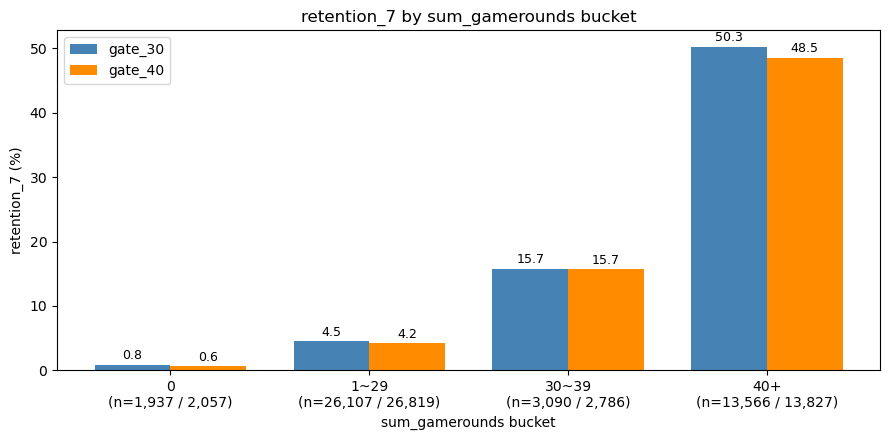

In [21]:
seg = segment[segment['sample'] == 'all'].reset_index(drop=True)
x = np.arange(len(seg))
w = 0.38

fig, ax = plt.subplots(figsize=(9, 4.5))
for offset, g, color in [(-w / 2, 'gate_30', 'steelblue'), (w / 2, 'gate_40', 'darkorange')]:
    bars = ax.bar(x + offset, seg[f'ret7_{g}_pct'], w, label=g, color=color)
    ax.bar_label(bars, fmt='%.1f', padding=2, fontsize=9)
ax.set_xticks(x, [f'{b}\n(n={n30:,} / {n40:,})' for b, n30, n40
                  in zip(seg['rounds_bucket'], seg['n_gate_30'], seg['n_gate_40'])])
ax.set_xlabel('sum_gamerounds bucket')
ax.set_ylabel('retention_7 (%)')
ax.set_title('retention_7 by sum_gamerounds bucket')
ax.legend()
plt.tight_layout()
plt.show()

### 7단계 해석

탐색적 관찰로, 7일 리텐션 차이는 40라운드 이상 구간에서 1.78%p로 가장 컸다. 하지만 이 구간의 gate_30 유저는 이미 게이트를 한 번 넘긴 유저라, 게이트 효과인지 원래 충성고객인지 차이를 구분할 수 없다. 30~39라운드 구간은 리텐션 차이가 0.04%p로 작았지만, 유저 수가 gate_30에서 약 300명 많아 게이트를 만난 유저가 이 구간에서 멈췄을 가능성이 있다. 라운드 수는 레벨이 아닌 게임 플레이 횟수라 레벨 위치와 정확히 일치하지 않는다. 실험한 위치는 30과 40뿐이라 30보다 게이트 레벨을 앞당길 경우의 효과는 알 수 없으므로 다음 실험(20·25·30 게이트 레벨) 과제로 남긴다.

## 8. 결과 요약

1~7단계 핵심 결과를 한 표로 모은다. 값은 앞 단계에서 계산한 변수(`p_srm`, `test_result`, `boot_result`, `effect_size`, `segment`)를 그대로 가져온다.

- 리텐션 관련 값은 극단값 포함(`all`) 기준. 극단값 제외(`excl_extreme`)와의 차이는 0.01%p 이내 (5·6단계 표 참고)
- 차이는 모두 gate_30 − gate_40 (%p)

In [22]:
def pick(df, metric, sample='all'):
    return df[(df['metric'] == metric) & (df['sample'] == sample)].iloc[0]

r7z, r1z = pick(test_result, 'retention_7 (주지표)'), pick(test_result, 'retention_1 (보조)')
r7b, r1b = pick(boot_result, 'retention_7 (주지표)'), pick(boot_result, 'retention_1 (보조)')
eff = effect_size.set_index('구분')
seg40 = segment[(segment['sample'] == 'all') & (segment['rounds_bucket'] == '40+')].iloc[0]
seg3039 = segment[(segment['sample'] == 'all') & (segment['rounds_bucket'] == '30~39')].iloc[0]

def ret_rows(label, z, b):
    return [
        (label, '비율 gate_30 / gate_40', f"{z['gate_30 (%)']:.2f}% / {z['gate_40 (%)']:.2f}%"),
        (label, '차이', f"{z['diff (%p)']:.2f}%p"),
        (label, 'z검정 95% CI', f"[{z['CI 95% low (%p)']:.2f}, {z['CI 95% high (%p)']:.2f}]%p"),
        (label, 'z검정 p값', f"{z['p_value']:.4f}"),
        (label, '부트스트랩 95% 구간', f"[{b['boot 2.5% (%p)']:.2f}, {b['boot 97.5% (%p)']:.2f}]%p"),
        (label, 'gate_30 우위 비율 (부트스트랩)', f"{b['P(gate_30 > gate_40)'] * 100:.2f}%"),
    ]

summary_rows = [
    ('3. SRM', '유저 수 gate_30 / gate_40', f"{observed[0]:,} / {observed[1]:,}"),
    ('3. SRM', '카이제곱 적합도 검정', f'chi2 = {chi2:.3f}, p = {p_srm:.4f}'),
    *ret_rows('5·6. retention_7 (주지표)', r7z, r7b),
    *ret_rows('5·6. retention_1 (보조)', r1z, r1b),
    ('6. 효과 크기 (retention_7)', '상대 변화 gate_40 vs gate_30',
     f"{eff.loc['점추정', '상대 변화 gate_40 vs gate_30 (%)']:.2f}% "
     f"(z CI 기준 {eff.loc['z CI 하한', '상대 변화 gate_40 vs gate_30 (%)']:.2f} ~ "
     f"{eff.loc['z CI 상한', '상대 변화 gate_40 vs gate_30 (%)']:.2f}%)"),
    ('6. 효과 크기 (retention_7)', '신규 유저 1만 명당 7일 재방문 감소',
     f"{eff.loc['점추정', '1만 명당 7일 재방문 감소 (명)']:.0f}명 "
     f"(z CI 기준 {eff.loc['z CI 하한', '1만 명당 7일 재방문 감소 (명)']:.0f} ~ "
     f"{eff.loc['z CI 상한', '1만 명당 7일 재방문 감소 (명)']:.0f}명)"),
    ('7. 세그먼트 (탐색적)', '40+ 라운드 retention_7 차이', f"{seg40['diff_pp']:.2f}%p"),
    ('7. 세그먼트 (탐색적)', '30~39 라운드 retention_7 차이 / 유저 수',
     f"{seg3039['diff_pp']:.2f}%p / {seg3039['n_gate_30']:,} vs {seg3039['n_gate_40']:,}"),
]

final_summary = pd.DataFrame(summary_rows, columns=['단계', '항목', '값'])
final_summary.style.hide(axis='index')

단계,항목,값
3. SRM,유저 수 gate_30 / gate_40,"44,700 / 45,489"
3. SRM,카이제곱 적합도 검정,"chi2 = 6.902, p = 0.0086"
5·6. retention_7 (주지표),비율 gate_30 / gate_40,19.02% / 18.20%
5·6. retention_7 (주지표),차이,0.82%p
5·6. retention_7 (주지표),z검정 95% CI,"[0.31, 1.33]%p"
5·6. retention_7 (주지표),z검정 p값,0.0016
5·6. retention_7 (주지표),부트스트랩 95% 구간,"[0.32, 1.33]%p"
5·6. retention_7 (주지표),gate_30 우위 비율 (부트스트랩),99.93%
5·6. retention_1 (보조),비율 gate_30 / gate_40,44.82% / 44.23%
5·6. retention_1 (보조),차이,0.59%p


### 결론

게이트를 40레벨로 옮기지 않는다. 주지표인 7일 리텐션이 0.82%p(상대 4.3%) 낮아지고, z검정과 부트스트랩 두 방법 모두 같은 결론을 보였기 때문이다. 1일 리텐션은 차이를 확인하지 못했고, 게이트 위치 이동의 효과는 첫날보다 7일 뒤 재방문에서 나타났다.

### 한계

1. SRM 검정에서 p=0.0086으로 그룹 비율이 50:50에서 약간 벗어났다. 사전 기준(0.001)에는 해당하지 않아 분석을 진행했지만, 배정 과정을 확인할 수 없는 공개 데이터라 한계로 남긴다.
2. 관측 지표가 1일, 7일 리텐션과 라운드 수뿐이라 매출에 대한 영향을 알 수 없다.
3. 실험 게이트 위치가 30과 40레벨뿐이라 다른 위치의 효과는 알 수 없다.
4. 라운드 수는 플레이 횟수라 레벨과 일치하지 않아, 세그먼트 해석에 한계가 있다.

## 9. 다음 실험: 3일 출석 미션 A/B 표본 크기

두 비율 비교에 필요한 그룹당 표본 수를 `statsmodels`의 `NormalIndPower`로 계산한다.

- 기준 결제율: 0.387 (이전 프로젝트 관측값)
- 유의수준 0.05, 검정력 0.8, 양측, 두 그룹 1:1
- 최소 검출 차이(MDE): 3%p, 5%p
- 효과 크기는 Cohen's h (`proportion_effectsize`)로 변환해서 넣는다
- 같은 차이라도 비율이 0.5에 가까울수록 분산이 커서 표본이 더 필요하다. 그래서 결제율이 오르는 방향(+)을 기준으로 보고, 내려가는 방향(−)은 참고로 함께 표시

In [23]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

p_base = 0.387  # 이전 프로젝트 관측값
ALPHA, POWER = 0.05, 0.8

power_rows = []
for mde in [0.03, 0.05]:
    for direction, sign in [('증가 (+)', 1), ('감소 (−, 참고)', -1)]:
        p_target = p_base + sign * mde
        h = proportion_effectsize(p_target, p_base)
        n = NormalIndPower().solve_power(effect_size=abs(h), alpha=ALPHA, power=POWER,
                                         ratio=1, alternative='two-sided')
        power_rows.append({
            'MDE (%p)': round(mde * 100),
            '방향': direction,
            '기준 결제율': p_base,
            '목표 결제율': round(p_target, 4),
            "Cohen's h": round(abs(h), 4),
            '그룹당 표본 수': int(np.ceil(n)),
            '전체 표본 수 (2그룹)': int(np.ceil(n)) * 2,
        })

sample_size = pd.DataFrame(power_rows)
print(f'기준 결제율 = {p_base} (이전 프로젝트 관측값)')
sample_size

기준 결제율 = 0.387 (이전 프로젝트 관측값)


,MDE (%p),방향,기준 결제율,목표 결제율,Cohen's h,그룹당 표본 수,전체 표본 수 (2그룹)
0,3,증가 (+),0.387,0.417,0.0612,4192,8384
1,3,"감소 (−, 참고)",0.387,0.357,0.0621,4074,8148
2,5,증가 (+),0.387,0.437,0.1016,1520,3040
3,5,"감소 (−, 참고)",0.387,0.337,0.1041,1449,2898


### 9-1. 설계안 (무작위 단위, 주지표, 가드레일, 기간)

(본인 작성)